In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind as t_test
from scipy.stats import t as t

In [82]:
df_users = pd.read_excel('dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx', sheet_name=0)
df_payments = pd.read_excel('dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx', sheet_name=1)

In [83]:
df_users.describe(include='all')

,user_id,group,age,city,device_type
count,1504.000000,1503,1504.000000,1503,1504
unique,NaN,2,NaN,3,2
top,NaN,A,NaN,Москва,android
freq,NaN,752,NaN,595,777
mean,1769.787234,NaN,32.745346,NaN,NaN
std,571.592080,NaN,8.410915,NaN,NaN
min,1001.000000,NaN,-5.000000,NaN,NaN
25%,1376.750000,NaN,27.000000,NaN,NaN
50%,1752.500000,NaN,33.000000,NaN,NaN
75%,2128.250000,NaN,38.000000,NaN,NaN


In [84]:
df_payments.describe(include='all')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
count,2661.000000,2660.000000,2661,2661,2256,1719,1522
unique,NaN,NaN,2,NaN,NaN,NaN,NaN
top,NaN,NaN,B,NaN,NaN,NaN,NaN
freq,NaN,NaN,1352,NaN,NaN,NaN,NaN
mean,6433.978579,1760.884211,NaN,2024-04-15 17:56:46.854566,2024-04-15 14:21:25.904255,2024-04-15 13:37:05.375218,2024-04-15 12:22:53.534822
min,5001.000000,1001.000000,NaN,2024-04-01 00:19:00,2024-04-01 00:23:00,2024-04-01 00:29:00,2024-04-01 00:33:00
25%,5666.000000,1388.000000,NaN,2024-04-08 01:30:00,2024-04-07 22:25:45,2024-04-07 19:01:00,2024-04-07 22:22:00
50%,6331.000000,1762.500000,NaN,2024-04-15 15:30:00,2024-04-15 05:12:30,2024-04-15 05:23:00,2024-04-14 23:01:00
75%,6996.000000,2135.250000,NaN,2024-04-23 13:25:00,2024-04-23 12:43:00,2024-04-23 14:28:00,2024-04-23 11:49:30
max,99003.000000,9004.000000,NaN,2024-04-30 23:17:00,2024-04-30 23:20:00,2024-04-30 23:25:00,2024-04-30 23:30:00


In [85]:
print(df_users['device_type'].value_counts().sum())
print(df_users['group'].value_counts().sum())
print(df_users['city'].value_counts().sum())
print(df_users['user_id'].value_counts().sum())
print(len(df_users))


1504
1503
1503
1504
1504


In [86]:
df_users_clean = df_users[(df_users['age'] >= 18) & (df_users['age'] <= 100)]


In [87]:
df_users_clean = df_users_clean.dropna() 

In [88]:
print(df_users_clean['device_type'].value_counts().sum())
print(df_users_clean['group'].value_counts(), df_users_clean['group'].value_counts().sum())
print(df_users_clean['city'].value_counts().sum())
print(df_users_clean['user_id'].value_counts().sum())
print(df_users_clean['user_id'].nunique())
print(len(df_users_clean))

1500
group
A    750
B    750
Name: count, dtype: int64 1500
1500
1500
1500
1500


In [89]:
print(df_payments['payment_id'].value_counts().sum())
print(df_payments['user_id'].value_counts().sum())
print(df_payments['group'].value_counts(), df_payments['group'].value_counts().sum())
print(df_payments['step1_opened'].value_counts().sum())
print(len(df_payments))

2661
2660
group
B    1352
A    1309
Name: count, dtype: int64 2661
2661
2661


In [90]:
df_payments_clean = df_payments.dropna(subset = 'user_id')
print(df_payments_clean['payment_id'].value_counts().sum())
print(df_payments_clean['payment_id'].nunique())
print(df_payments_clean['user_id'].value_counts().sum())
print(df_payments_clean['group'].value_counts(), df_payments_clean['group'].value_counts().sum())
print(df_payments_clean['step1_opened'].value_counts().sum())
print(len(df_payments_clean))

2660
2660
2660
group
B    1352
A    1308
Name: count, dtype: int64 2660
2660
2660


In [91]:
df_users_clean

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios
...,...,...,...,...,...
1495,2496,B,27,Москва,android
1496,2497,B,33,Москва,android
1497,2498,B,28,СПб,ios
1498,2499,B,42,Москва,ios


In [92]:
df_payments_clean

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00
...,...,...,...,...,...,...,...
2655,7656,2499.0,B,2024-04-24 20:54:00,2024-04-24 21:00:00,2024-04-24 21:03:00,2024-04-24 21:08:00
2656,7657,2500.0,B,2024-04-11 07:01:00,2024-04-11 07:04:00,NaT,NaT
2657,7658,9004.0,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00


In [126]:
df_payments_clean['step2_complete'] = df_payments_clean['step2_entered'].notna()
df_payments_clean['step3_complete'] = df_payments_clean['step3_confirmed'].notna()
df_payments_clean['is_success'] = df_payments_clean['step4_success'].notna()
df_payments_clean

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,is_success,step2_success,step3_success,step2_complete,step3_complete
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT,False,True,False,True,False
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT,False,True,False,True,False
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT,False,True,False,True,False
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT,False,False,False,False,False
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...
2655,7656,2499.0,B,2024-04-24 20:54:00,2024-04-24 21:00:00,2024-04-24 21:03:00,2024-04-24 21:08:00,True,True,True,True,True
2656,7657,2500.0,B,2024-04-11 07:01:00,2024-04-11 07:04:00,NaT,NaT,False,True,False,True,False
2657,7658,9004.0,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00,True,True,True,True,True
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00,True,True,True,True,True


In [152]:
result = df_payments_clean.groupby('user_id').agg(
    step2_sum = ('step2_complete', 'sum'),
    step3_sum = ('step3_complete', 'sum'),
    success_sum=('is_success', 'sum'),
    try_count=('user_id', 'count')
).sort_values(by='try_count', ascending=False)
result['step2_rate'] = result['step2_sum']/result['try_count']
result['step3_rate'] = result['step3_sum']/result['try_count']
result['success_rate'] = result['success_sum']/result['try_count']
result = result.reset_index()
result

,user_id,step2_sum,step3_sum,success_sum,try_count,step2_rate,step3_rate,success_rate
0,1381.0,3,2,2,4,0.75,0.50,0.50
1,1321.0,4,4,4,4,1.00,1.00,1.00
2,2434.0,4,3,3,4,1.00,0.75,0.75
3,1323.0,3,3,3,4,0.75,0.75,0.75
4,2490.0,4,3,2,4,1.00,0.75,0.50
...,...,...,...,...,...,...,...,...
1496,2471.0,1,1,1,1,1.00,1.00,1.00
1497,1028.0,1,0,0,1,1.00,0.00,0.00
1498,2487.0,1,1,1,1,1.00,1.00,1.00
1499,2489.0,1,1,1,1,1.00,1.00,1.00


In [153]:
df_final = df_users_clean.merge(
    result[['user_id', 'step2_rate', 'step3_rate', 'success_rate']], 
    on='user_id', 
    how='left'
)
df_final

,user_id,group,age,city,device_type,step2_rate,step3_rate,success_rate
0,1001,A,31,Москва,ios,1.000000,0.000000,0.000000
1,1002,A,31,Москва,ios,1.000000,0.000000,0.000000
2,1003,A,25,Москва,android,1.000000,0.000000,0.000000
3,1004,A,20,Москва,ios,0.666667,0.666667,0.666667
4,1005,A,34,Москва,ios,1.000000,0.500000,0.500000
...,...,...,...,...,...,...,...,...
1495,2496,B,27,Москва,android,1.000000,1.000000,1.000000
1496,2497,B,33,Москва,android,0.000000,0.000000,0.000000
1497,2498,B,28,СПб,ios,1.000000,1.000000,1.000000
1498,2499,B,42,Москва,ios,1.000000,1.000000,1.000000


In [164]:

groups_result = df_final.groupby('group').agg(
        step2_mean=('step2_rate', 'mean'),
        step3_mean=('step3_rate', 'mean'),
        success_mean=('success_rate', 'mean')
)
groups_result = groups_result.reset_index()
groups_result

,group,step2_mean,step3_mean,success_mean
0,A,0.814333,0.584667,0.502333
1,B,0.889222,0.727444,0.655333


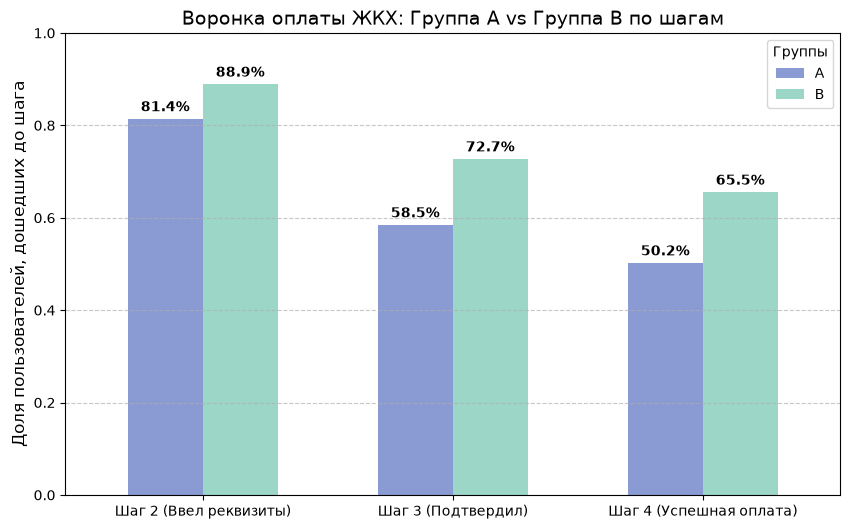

In [199]:
hist_result = groups_result.set_index('group').T

step_names = ['Шаг 2 (Ввел реквизиты)', 'Шаг 3 (Подтвердил)', 'Шаг 4 (Успешная оплата)']
hist_result.index = step_names

ax = hist_result.plot(kind='bar', figsize=(10, 6), color=["#8A9BD4", "#9bd6c7"], width=0.6)

plt.title('Воронка оплаты ЖКХ: Группа А vs Группа B по шагам', fontsize=14)
plt.ylabel('Доля пользователей, дошедших до шага', fontsize=12)
plt.xlabel('')
plt.xticks(rotation=0)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1%}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 8), 
                textcoords='offset points', 
                fontsize=10, fontweight='bold')

plt.legend(title='Группы')
plt.show()

In [200]:
data_A = df_final[df_final['group'] == 'A']['success_rate']
data_B = df_final[df_final['group'] == 'B']['success_rate']

t_stat, p_value = t_test(data_A, data_B, equal_var=False)

print(p_value)

5.569042727680183e-13


In [201]:
A_rate = groups_result[groups_result['group'] == 'A']['success_mean'].item()
B_rate = groups_result[groups_result['group'] == 'B']['success_mean'].item()

reletive_dif = B_rate/A_rate
absolut_dif = B_rate - A_rate

print(f'reletive = {reletive_dif:.1%}')
print(f'absolute = {absolut_dif:.3f}')

reletive = 130.5%
absolute = 0.153


In [ ]:
n_A = len(data_A)
n_B = len(data_B)
var_A = data_A.var(ddof=1)
var_B = data_B.var(ddof=1)

se_diff = np.sqrt(var_A/n_A + var_B/n_B)
dof = ((var_A/n_A + var_B/n_B)**2) / (((var_A/n_A)**2)/(n_A-1) + ((var_B/n_B)**2)/(n_B-1))
t_crit = t.ppf(0.975, dof)

ci_lower = absolut_dif - t_crit * se_diff
ci_upper = absolut_dif + t_crit * se_diff

print(f"95% CI in [{ci_lower:.4f}, {ci_upper:.4f}]")

95% CI in [0.1117, 0.1943]
